# Trabajo Práctico 3 (TP3): Clasificación de Imágenes de Cáncer de Mama usando PCA y SVD

## Objetivo
El objetivo de este Trabajo Práctico es aplicar los conceptos de reducción de dimensionalidad vistos en la Clase 8 (**SVD y PCA**) para construir un clasificador de imágenes médicas. 

Trabajaremos con imágenes de ultrasonido de mama para clasificarlas en **Benignas** o **Malignas**.

## 1. Obtención del Dataset (BreastMNIST)
Para este TP utilizaremos **BreastMNIST**, un subconjunto del famoso dataset MedMNIST, el cual contiene imágenes de ultrasonido de mama de 28x28 píxeles en escala de grises.

**Instrucciones:** Si no tienes instalada la librería `medmnist`, ejecuta la siguiente celda.

In [ ]:
# !pip install medmnist

A continuación, descargaremos y cargaremos los datos de entrenamiento y prueba.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import medmnist
from medmnist import BreastMNIST

# Descargar y cargar los datos
train_dataset = BreastMNIST(split='train', download=True)
test_dataset = BreastMNIST(split='test', download=True)

# Extraer las imágenes y las etiquetas
X_train = train_dataset.imgs
y_train = train_dataset.labels.squeeze()

X_test = test_dataset.imgs
y_test = test_dataset.labels.squeeze()

print(f"Dimensiones de X_train: {X_train.shape}")
print(f"Dimensiones de X_test: {X_test.shape}")

100%|██████████| 560k/560k [00:01<00:00, 424kB/s] 

Dimensiones de X_train: (546, 28, 28)
Dimensiones de X_test: (156, 28, 28)


### Consigna 1: Visualización Exploratoria
Extrae y visualiza al menos 3 imágenes correspondientes a tumores benignos (etiqueta 0) y 3 imágenes a tumores malignos (etiqueta 1).
¿Notas alguna diferencia visual obvia entre ambas clases?

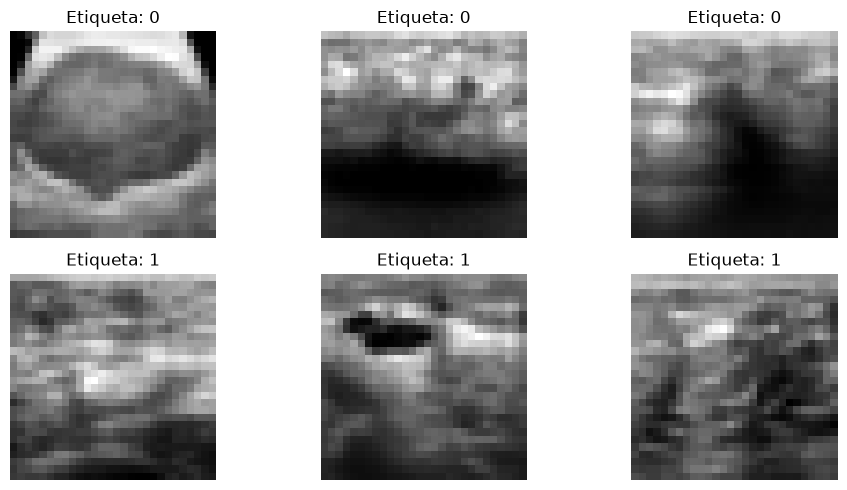

In [3]:
# Visualizar algunas imágenes de entrenamiento
plt.figure(figsize=(10, 5))
indices_por_etiqueta = np.concatenate([
    np.flatnonzero(y_train == etiqueta)[:3]
    for etiqueta in [0, 1]
])

for i, indice in enumerate(indices_por_etiqueta):
    plt.subplot(2, 3, i + 1)
    plt.imshow(X_train[indice], cmap='gray')
    plt.title(f"Etiqueta: {y_train[indice]}")
    plt.axis('off')
plt.tight_layout()
plt.show()

Honestamente no entiendo las imagenes pero los tumores malignos parecen mas irregulares que los benignos, tienen formas distintas incluso parece como si fuera tejido cicatrizado

## 2. Preprocesamiento y Vectorización
Para aplicar PCA o SVD estándar, necesitamos que cada imagen (una matriz 2D de 28x28) se convierta en un vector 1D (784 píxeles).

### Consigna 2: Vectorización y Centrado
1. Transforma `X_train` y `X_test` de dimensiones `(N, 28, 28)` a `(N, 784)`.
2. Calcula el **rostro (imagen) medio** del conjunto de entrenamiento y réstalo a todas las imágenes (tanto de train como de test) para centrar los datos.

In [4]:
# Normalizar y vectorizar las imágenes
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0
X_train = X_train.reshape(X_train.shape[0], -1)
X_test = X_test.reshape(X_test.shape[0], -1)

# Calcular la imagen media solo con entrenamiento y centrar ambos conjuntos
imagen_media = X_train.mean(axis=0)
X_train_centrado = X_train - imagen_media
X_test_centrado = X_test - imagen_media

print(f"Dimensiones de X_train vectorizado: {X_train.shape}")
print(f"Dimensiones de X_test vectorizado: {X_test.shape}")
print(f"Dimensión de la imagen media: {imagen_media.shape}")


Dimensiones de X_train vectorizado: (546, 784)
Dimensiones de X_test vectorizado: (156, 784)
Dimensión de la imagen media: (784,)


## 3. Reducción de Dimensionalidad con SVD / PCA
Ahora aplicaremos SVD a nuestra matriz de datos centrados para extraer los **Componentes Principales** (las "Eigen-imágenes").

### Consigna 3: Cálculo de SVD
1. Aplica SVD a la matriz de entrenamiento centrada para obtener `U`, `S` y `V^T`.
2. Grafica la varianza explicada acumulada y decide un valor de `r` (número de componentes) que conserve al menos el 90% de la energía/varianza.
3. Visualiza los primeros 5 componentes principales (Eigen-imágenes) redimensionándolos de nuevo a 28x28.

Componentes necesarios para conservar al menos el 90%: r = 36
Varianza acumulada con r componentes: 90.11%


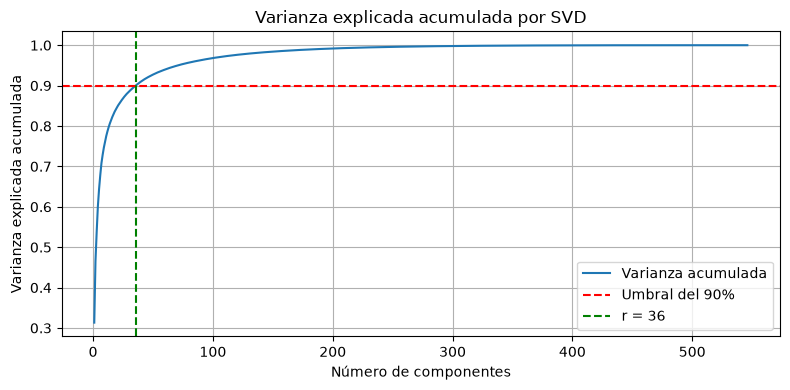

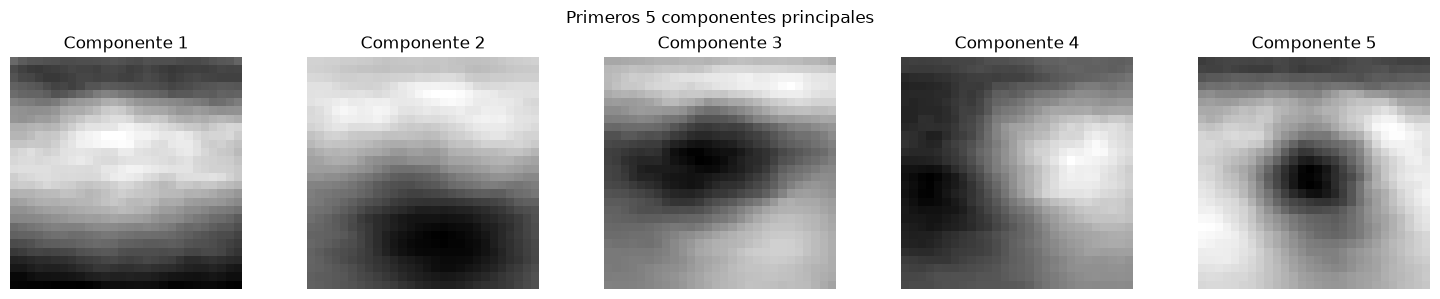

In [5]:
# Calcular la descomposición SVD de los datos de entrenamiento centrados
U, S, VT = np.linalg.svd(X_train_centrado, full_matrices=False)

# Calcular la varianza explicada acumulada y elegir r con al menos 90%
varianza_explicada = (S ** 2) / np.sum(S ** 2)
varianza_acumulada = np.cumsum(varianza_explicada)
r = np.searchsorted(varianza_acumulada, 0.90) + 1

print(f"Componentes necesarios para conservar al menos el 90%: r = {r}")
print(f"Varianza acumulada con r componentes: {varianza_acumulada[r - 1]:.2%}")

plt.figure(figsize=(8, 4))
plt.plot(
    np.arange(1, len(varianza_acumulada) + 1),
    varianza_acumulada,
    label='Varianza acumulada',
)
plt.axhline(0.90, color='red', linestyle='--', label='Umbral del 90%')
plt.axvline(r, color='green', linestyle='--', label=f'r = {r}')
plt.xlabel('Número de componentes')
plt.ylabel('Varianza explicada acumulada')
plt.title('Varianza explicada acumulada por SVD')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Visualizar los primeros 5 componentes principales como imágenes 28x28
fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for i, ax in enumerate(axes):
    ax.imshow(VT[i].reshape(28, 28), cmap='gray')
    ax.set_title(f'Componente {i + 1}')
    ax.axis('off')
fig.suptitle('Primeros 5 componentes principales')
plt.tight_layout()
plt.show()


## 4. Proyección y Clasificación
Una vez que tenemos la matriz de proyección (los primeros `r` componentes de `V^T` o equivalentemente usando Scikit-Learn `PCA`), proyectaremos los datos a un espacio de menor dimensión.

### Consigna 4: Clasificador Predictivo
1. Proyecta `X_train_centrado` y `X_test_centrado` sobre los primeros `r` componentes principales.
2. Entrena un clasificador simple, como **Regresión Logística** o **k-Nearest Neighbors (k-NN)**, usando las proyecciones de entrenamiento.
3. Evalúa el modelo en el conjunto de prueba usando `accuracy_score` y `classification_report`.
4. Prueba variar el número de componentes `r` (ej: 5, 20, 50) y describe cómo afecta el rendimiento.

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

# Evaluar diferentes cantidades de componentes principales
componentes_a_evaluar = [5, 20, 50]
resultados = {}

for cantidad_componentes in componentes_a_evaluar:
    X_train_proyectado = X_train_centrado @ VT[:cantidad_componentes].T
    X_test_proyectado = X_test_centrado @ VT[:cantidad_componentes].T

    modelo = LogisticRegression(max_iter=1000, random_state=42)
    modelo.fit(X_train_proyectado, y_train)
    y_pred = modelo.predict(X_test_proyectado)

    accuracy = accuracy_score(y_test, y_pred)
    resultados[cantidad_componentes] = accuracy

    print(f"\n===== {cantidad_componentes} componentes =====")
    print(f"Accuracy: {accuracy:.4f}")
    print(classification_report(y_test, y_pred, zero_division=0))

# Usar r, elegido en la Consigna 3, para la proyección principal
X_train_proyectado = X_train_centrado @ VT[:r].T
X_test_proyectado = X_test_centrado @ VT[:r].T

modelo = LogisticRegression(max_iter=1000, random_state=42)
modelo.fit(X_train_proyectado, y_train)
y_pred = modelo.predict(X_test_proyectado)

print(f"\n===== Modelo final con r = {r} componentes =====")
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(classification_report(y_test, y_pred, zero_division=0))



===== 5 componentes =====
Accuracy: 0.8013
              precision    recall  f1-score   support

           0       0.82      0.33      0.47        42
           1       0.80      0.97      0.88       114

    accuracy                           0.80       156
   macro avg       0.81      0.65      0.68       156
weighted avg       0.81      0.80      0.77       156


===== 20 componentes =====
Accuracy: 0.7949
              precision    recall  f1-score   support

           0       0.78      0.33      0.47        42
           1       0.80      0.96      0.87       114

    accuracy                           0.79       156
   macro avg       0.79      0.65      0.67       156
weighted avg       0.79      0.79      0.76       156


===== 50 componentes =====
Accuracy: 0.7949
              precision    recall  f1-score   support

           0       0.73      0.38      0.50        42
           1       0.81      0.95      0.87       114

    accuracy                           0.79     

### Consigna Opcional (Bonus)
Implementa un clasificador que, en lugar de usar un modelo externo como Regresión Logística, utilice directamente la reconstrucción de PCA. Por ejemplo, midiendo el error de reconstrucción de una imagen de prueba usando los componentes calculados únicamente sobre imágenes benignas vs imágenes malignas.

In [7]:
def calcular_base_pca_por_etiqueta(X, y, etiqueta, cantidad_componentes):
    """Calcula la media y los componentes PCA de una etiqueta."""
    X_clase = X[y == etiqueta]
    media_clase = X_clase.mean(axis=0)
    X_clase_centrada = X_clase - media_clase
    _, _, VT_clase = np.linalg.svd(X_clase_centrada, full_matrices=False)
    componentes = VT_clase[:cantidad_componentes]
    return media_clase, componentes


def calcular_error_reconstruccion(X, media, componentes):
    """Calcula el error cuadrático medio de reconstrucción de cada imagen."""
    X_centrada = X - media
    proyeccion = X_centrada @ componentes.T
    reconstruccion = media + proyeccion @ componentes
    return np.mean((X - reconstruccion) ** 2, axis=1)


# Se calcula una base PCA independiente para cada etiqueta usando solo train.
media_benigna, componentes_benigna = calcular_base_pca_por_etiqueta(
    X_train, y_train, etiqueta=0, cantidad_componentes=r
)
media_maligna, componentes_maligna = calcular_base_pca_por_etiqueta(
    X_train, y_train, etiqueta=1, cantidad_componentes=r
)

error_benigna = calcular_error_reconstruccion(
    X_test, media_benigna, componentes_benigna
)
error_maligna = calcular_error_reconstruccion(
    X_test, media_maligna, componentes_maligna
)

# Se asigna la etiqueta cuya base PCA reconstruye mejor cada imagen.
y_pred_reconstruccion = (error_maligna < error_benigna).astype(int)
accuracy_reconstruccion = accuracy_score(y_test, y_pred_reconstruccion)

print(f"Accuracy del clasificador por reconstrucción: {accuracy_reconstruccion:.4f}")
print(classification_report(y_test, y_pred_reconstruccion, zero_division=0))


Accuracy del clasificador por reconstrucción: 0.7692
              precision    recall  f1-score   support

           0       0.60      0.43      0.50        42
           1       0.81      0.89      0.85       114

    accuracy                           0.77       156
   macro avg       0.70      0.66      0.68       156
weighted avg       0.75      0.77      0.76       156

